In [1]:
# import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix


In [26]:
# Load the E-commerce customer behavior dataset into a Pandas DataFrame.
df = pd.read_csv("ecommerce_customer_behavior_dataset_v2.csv")
df_copy = df.copy()

In [27]:
# Display the first 10 observations
print(df_copy.head(10))

       Order_ID Customer_ID        Date  Age Gender      City  \
0  ORD_000001-1  CUST_00001  2023-05-29   40   Male    Ankara   
1  ORD_000001-2  CUST_00001  2023-10-12   40   Male    Ankara   
2  ORD_000001-3  CUST_00001  2023-12-05   40   Male    Ankara   
3  ORD_000002-1  CUST_00002  2023-05-11   33   Male  Istanbul   
4  ORD_000002-2  CUST_00002  2023-06-16   33   Male  Istanbul   
5  ORD_000003-1  CUST_00003  2023-02-27   42   Male     Konya   
6  ORD_000003-2  CUST_00003  2024-01-03   42   Male     Konya   
7  ORD_000004-1  CUST_00004  2024-02-13   53   Male     Izmir   
8  ORD_000005-1  CUST_00005  2023-03-16   32   Male    Ankara   
9  ORD_000005-2  CUST_00005  2023-06-12   32   Male    Ankara   

  Product_Category  Unit_Price  Quantity  Discount_Amount  Total_Amount  \
0            Books       29.18         1             0.00         29.18   
1    Home & Garden      644.40         1           138.05        506.35   
2           Sports      332.82         5             0.00  

In [4]:
# determine the total number of rows and columns
print("Shape: ", df_copy.shape)
# display the column names and their corresponding data types
print("Column names and their corresponding data types:")
print(df_copy.dtypes)

Shape:  (17049, 18)
Column names and their corresponding data types:
Order_ID                     object
Customer_ID                  object
Date                         object
Age                           int64
Gender                       object
City                         object
Product_Category             object
Unit_Price                  float64
Quantity                      int64
Discount_Amount             float64
Total_Amount                float64
Payment_Method               object
Device_Type                  object
Session_Duration_Minutes      int64
Pages_Viewed                  int64
Is_Returning_Customer          bool
Delivery_Time_Days            int64
Customer_Rating               int64
dtype: object


In [5]:
# Calculate the number of missing values in each column and check for duplicate observations
print("Missing values:\n", df_copy.isna().sum())
print("Duplicate values: ", df_copy.duplicated().sum())

Missing values:
 Order_ID                    0
Customer_ID                 0
Date                        0
Age                         0
Gender                      0
City                        0
Product_Category            0
Unit_Price                  0
Quantity                    0
Discount_Amount             0
Total_Amount                0
Payment_Method              0
Device_Type                 0
Session_Duration_Minutes    0
Pages_Viewed                0
Is_Returning_Customer       0
Delivery_Time_Days          0
Customer_Rating             0
dtype: int64
Duplicate values:  0


In [6]:
# Identify possible outliers in Age using the IQR method
Q1 = df_copy["Age"].quantile(0.25)
Q3 = df_copy["Age"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

age_outliers = df_copy[(df_copy["Age"] < lower_bound) | (df_copy["Age"] > upper_bound)]
print(age_outliers["Age"])

585      67
586      67
587      67
588      67
691      75
692      75
693      75
694      75
695      75
696      75
1573     71
5593     73
6731     72
7004     68
7005     68
7869     72
8579     70
8580     70
8625     70
8626     70
8627     70
8628     70
8629     70
9509     67
9510     67
9511     67
9861     75
9862     75
9863     75
9864     75
11041    69
11042    69
11043    69
12609    73
13519    72
13520    72
13521    72
13522    72
13523    72
13740    68
13741    68
16334    68
16335    68
16336    68
16656    71
16657    71
16658    71
16659    71
16660    71
17043    72
Name: Age, dtype: int64


In [7]:
# Identify possible outliers in Unit Price using the IQR method
Q1 = df_copy["Unit_Price"].quantile(0.25)
Q3 = df_copy["Unit_Price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

age_outliers = df_copy[(df_copy["Unit_Price"] < lower_bound) | (df_copy["Unit_Price"] > upper_bound)]
print(age_outliers["Unit_Price"])

16       1197.86
35       1880.69
37       4537.80
83       2976.00
84       1297.30
          ...   
17012    1822.71
17017    1969.28
17020    2113.52
17026    2007.72
17040    3109.97
Name: Unit_Price, Length: 1757, dtype: float64


In [8]:
# Identify possible outliers in Quantity using the IQR method
Q1 = df_copy["Quantity"].quantile(0.25)
Q3 = df_copy["Quantity"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

age_outliers = df_copy[(df_copy["Quantity"] < lower_bound) | (df_copy["Quantity"] > upper_bound)]
print(age_outliers["Quantity"])

Series([], Name: Quantity, dtype: int64)


In [9]:
# Identify possible outliers in Discount Amount using the IQR method
Q1 = df_copy["Discount_Amount"].quantile(0.25)
Q3 = df_copy["Discount_Amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

age_outliers = df_copy[(df_copy["Discount_Amount"] < lower_bound) | (df_copy["Discount_Amount"] > upper_bound)]
print(age_outliers["Discount_Amount"])

1        138.05
7         97.78
14       142.95
15       190.15
26       208.58
          ...  
17022    650.43
17025     93.77
17027    275.58
17028    549.22
17048    217.01
Name: Discount_Amount, Length: 2789, dtype: float64


In [10]:
# Identify possible outliers in Total Amount using the IQR method
Q1 = df_copy["Total_Amount"].quantile(0.25)
Q3 = df_copy["Total_Amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

age_outliers = df_copy[(df_copy["Total_Amount"] < lower_bound) | (df_copy["Total_Amount"] > upper_bound)]
print(age_outliers["Total_Amount"])

16        4791.44
35        5642.07
37       10861.25
40        4553.15
58        4250.96
           ...   
17017     7877.12
17026     8030.88
17040    12439.88
17046     3195.72
17048     3843.91
Name: Total_Amount, Length: 1943, dtype: float64


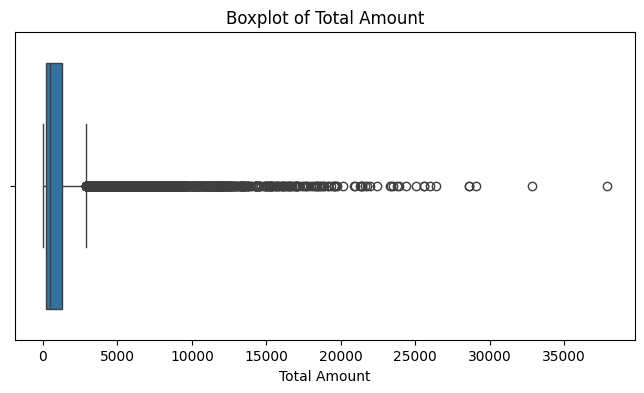

In [70]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df_copy["Total_Amount"])

plt.title("Boxplot of Total Amount")
plt.xlabel("Total Amount")
plt.show()

count    17049.000000
mean      1277.438711
std       2358.436375
min          6.210000
25%        172.970000
50%        455.850000
75%       1267.750000
max      37852.050000
Name: Total_Amount, dtype: float64


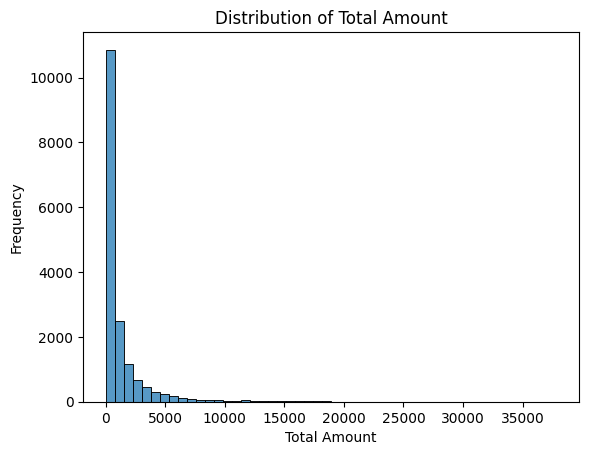

In [71]:
print(df_copy["Total_Amount"].describe())

sns.histplot(df_copy["Total_Amount"], bins=50)
plt.title("Distribution of Total Amount")
plt.xlabel("Total Amount")
plt.ylabel("Frequency")
plt.show()

In [12]:
# Identify possible outliers in Session Duration Minutes using the IQR method
Q1 = df_copy["Session_Duration_Minutes"].quantile(0.25)
Q3 = df_copy["Session_Duration_Minutes"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

age_outliers = df_copy[(df_copy["Session_Duration_Minutes"] < lower_bound) | (df_copy["Session_Duration_Minutes"] > upper_bound)]
print(age_outliers["Session_Duration_Minutes"])

345       6
498       6
784      26
880       6
954       5
         ..
15230    24
15795     5
15837     6
16100     6
16651     6
Name: Session_Duration_Minutes, Length: 85, dtype: int64


In [13]:
# Identify possible outliers in Pages Viewed using the IQR method
Q1 = df_copy["Pages_Viewed"].quantile(0.25)
Q3 = df_copy["Pages_Viewed"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

age_outliers = df_copy[(df_copy["Pages_Viewed"] < lower_bound) | (df_copy["Pages_Viewed"] > upper_bound)]
print(age_outliers["Pages_Viewed"])

13830    18
Name: Pages_Viewed, dtype: int64


In [14]:
# Identify possible outliers in Delivery Time using the IQR method
Q1 = df_copy["Delivery_Time_Days"].quantile(0.25)
Q3 = df_copy["Delivery_Time_Days"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

age_outliers = df_copy[(df_copy["Delivery_Time_Days"] < lower_bound) | (df_copy["Delivery_Time_Days"] > upper_bound)]
print(age_outliers["Delivery_Time_Days"])

105      15
135      16
229      15
235      15
257      19
         ..
16850    16
16895    18
16953    15
16990    16
17028    19
Name: Delivery_Time_Days, Length: 475, dtype: int64


In [15]:
# Calculate descriptive statistics for numerical e-commerce variables
numeric_cols = ["Age", "Unit_Price", "Quantity", "Discount_Amount", "Total_Amount", "Session_Duration_Minutes", "Pages_Viewed", "Delivery_Time_Days"]

summary = df_copy[numeric_cols].agg(
    ['count', 'mean', 'median', 'std', 'var', 'min', 'max']
).T

summary['Q1'] = df_copy[numeric_cols].quantile(0.25)
summary['Q3'] = df_copy[numeric_cols].quantile(0.75)
summary['IQR'] = summary['Q3'] - summary['Q1']
summary['Range'] = summary['max'] - summary['min']
summary['Skewness'] = df_copy[numeric_cols].skew()
summary['Kurtosis'] = df_copy[numeric_cols].kurt()

display(summary.round(3))

,count,mean,median,std,var,min,max,Q1,Q3,IQR,Range,Skewness,Kurtosis
Age,17049.0,34.946,35.00,11.047,122.033,18.00,75.00,26.00,42.00,16.00,57.00,0.320,-0.401
Unit_Price,17049.0,447.902,174.68,722.320,521745.757,5.05,7900.01,73.26,494.57,421.31,7894.96,3.646,17.604
Quantity,17049.0,3.011,3.00,1.417,2.008,1.00,5.00,2.00,4.00,2.00,4.00,-0.012,-1.304
Discount_Amount,17049.0,69.788,0.00,240.705,57938.734,0.00,6538.29,0.00,32.71,32.71,6538.29,8.640,120.076
Total_Amount,17049.0,1277.439,455.85,2358.436,5562222.134,6.21,37852.05,172.97,1267.75,1094.78,37845.84,4.585,30.380
Session_Duration_Minutes,17049.0,14.536,15.00,2.926,8.559,4.00,26.00,13.00,17.00,4.00,22.00,-0.008,0.038
Pages_Viewed,17049.0,9.003,9.00,2.260,5.107,1.00,18.00,7.00,11.00,4.00,17.00,-0.033,-0.013
Delivery_Time_Days,17049.0,6.504,6.00,3.489,12.172,1.00,25.00,4.00,8.00,4.00,24.00,1.133,1.874


In [16]:
# Calculate average order value per transaction
avg_order_value = df_copy["Total_Amount"].mean()
print('The average order value per transaction is: ', avg_order_value)

The average order value per transaction is:  1277.4387113613702


In [17]:
# Calculate average customer spending
avg_customer_spending = df_copy.groupby("Customer_ID")["Total_Amount"].sum().mean()
print('Average total spending per customer: ', avg_customer_spending)

Average total spending per customer:  4355.810517999999


In [18]:
# Calculate the average time between consecutive orders from the same customer
df_copy["Date"] = pd.to_datetime(df_copy["Date"])
orders = df_copy.sort_values("Date")
avg_days = orders.groupby("Customer_ID")["Date"].diff().dt.days.mean()
print('The average time between consecutive orders from the same customer is ',avg_days)

The average time between consecutive orders from the same customer is  81.23943895758984


In [19]:
# Calculate the rating distribution
display(pd.DataFrame({
    'count': df_copy['Customer_Rating'].value_counts(),
    'percent': (100 * df_copy['Customer_Rating'].value_counts(normalize=True)).round(2)
}))

,count,percent
Customer_Rating,,
5,6260,36.72
4,5863,34.39
3,2658,15.59
2,1487,8.72
1,781,4.58


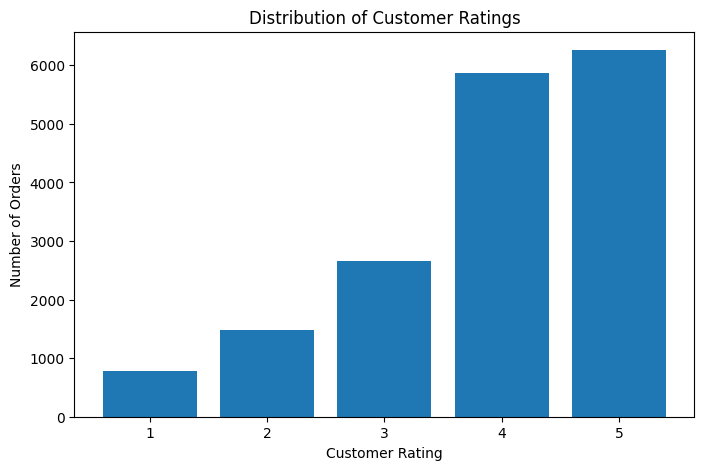

In [76]:
# Calculate the rating distribution
rating_counts = df_copy["Customer_Rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index, rating_counts.values)

plt.title("Distribution of Customer Ratings")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Orders")
plt.xticks([1, 2, 3, 4, 5])
plt.show()


In [20]:
# Calculate percentage of orders from returning customers
display(pd.DataFrame({
    'count': df_copy['Is_Returning_Customer'].value_counts(),
    'percent': (100 * df_copy['Is_Returning_Customer'].value_counts(normalize=True)).round(2)
}))

,count,percent
Is_Returning_Customer,,
True,15039,88.21
False,2010,11.79


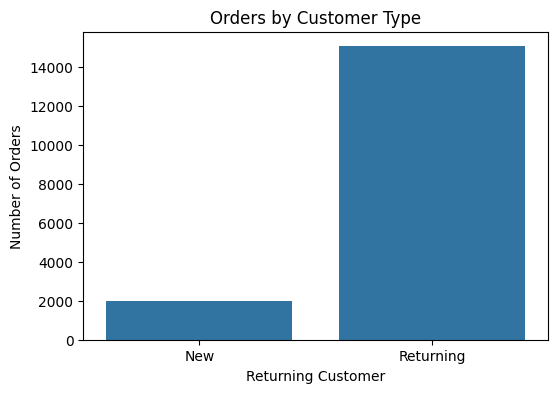

In [82]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df_copy,
    x="Is_Returning_Customer"
)

plt.title("Orders by Customer Type")
plt.xlabel("Returning Customer")
plt.ylabel("Number of Orders")
plt.xticks([0, 1], ["New", "Returning"])

plt.show()

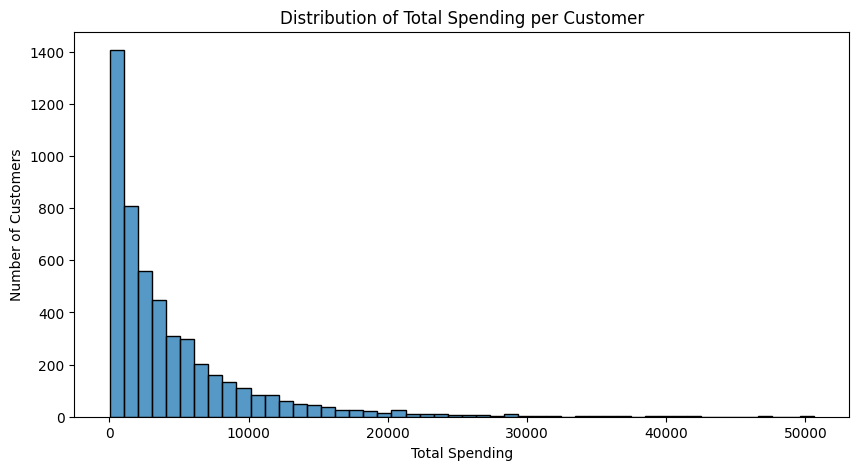

In [72]:
# Calculate total spending per customer
customer_spending = df_copy.groupby("Customer_ID")["Total_Amount"].sum()

plt.figure(figsize=(10, 5))
sns.histplot(customer_spending, bins=50)

plt.title("Distribution of Total Spending per Customer")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")
plt.show()

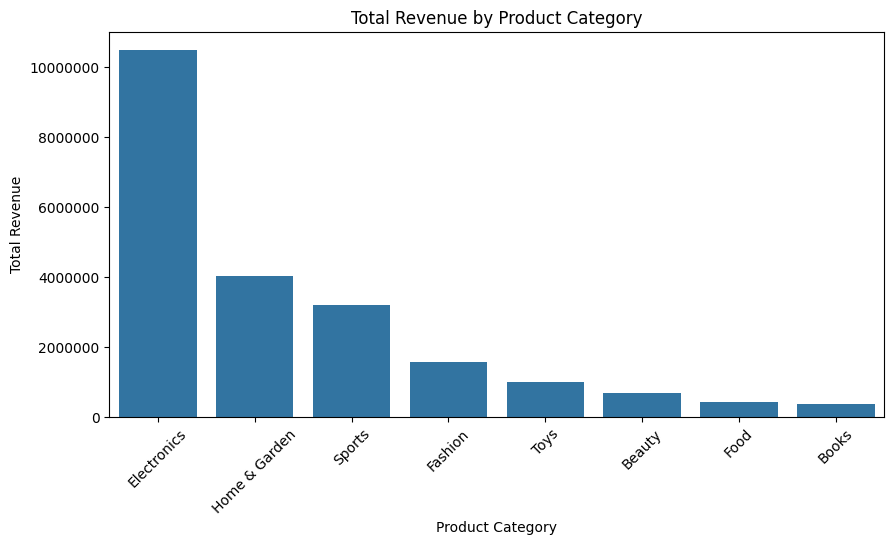

In [74]:
# Calculate total revenue by product category
revenue_by_category = (
    df_copy.groupby("Product_Category")["Total_Amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=revenue_by_category.index, y=revenue_by_category.values)

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.show()

In [ ]:
# Create a DataFrame of all unique customers in the dataset
customer_df = df_copy[["Customer_ID"]].drop_duplicates().reset_index(drop=True)

In [53]:
# Calculate recency for each customer
df_copy["Date"] = pd.to_datetime(df_copy["Date"])

reference_date = df_copy["Date"].max() + pd.Timedelta(days=1)

customer_df["Recency"] = (
    reference_date
    - customer_df["Customer_ID"].map(
        df_copy.groupby("Customer_ID")["Date"].max()
    )
).dt.days

display(customer_df[["Customer_ID", "Recency"]].head(10))

,Customer_ID,Recency
0,CUST_00001,112
1,CUST_00002,284
2,CUST_00003,83
3,CUST_00004,42
4,CUST_00005,279
5,CUST_00006,212
6,CUST_00007,81
7,CUST_00008,169
8,CUST_00009,39
9,CUST_00010,22


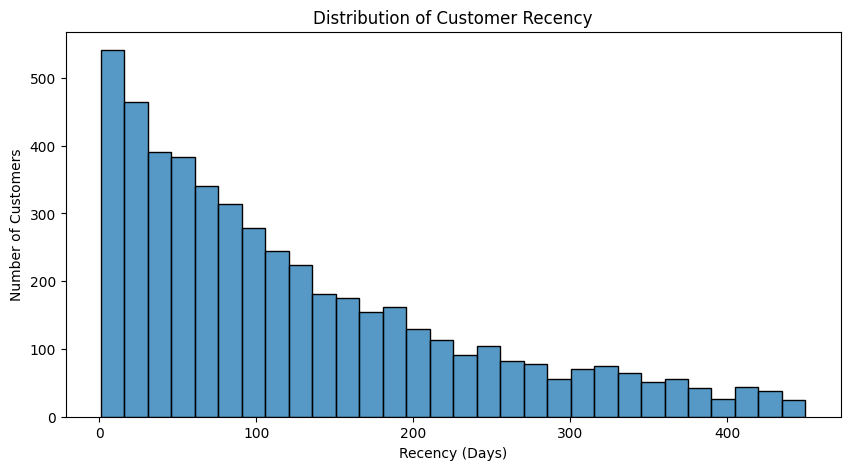

In [75]:
# Visualize customer recency distribution
plt.figure(figsize=(10, 5))
sns.histplot(customer_df["Recency"], bins=30)

plt.title("Distribution of Customer Recency")
plt.xlabel("Recency (Days)")
plt.ylabel("Number of Customers")
plt.show()

In [54]:
# Calculate purchase frequency for each customer
customer_df["Purchase_Frequency"] = (
    customer_df["Customer_ID"]
    .map(df_copy.groupby("Customer_ID")["Order_ID"].nunique())
)

display(customer_df[["Customer_ID", "Purchase_Frequency"]].head(10))

,Customer_ID,Purchase_Frequency
0,CUST_00001,3
1,CUST_00002,2
2,CUST_00003,2
3,CUST_00004,1
4,CUST_00005,3
5,CUST_00006,3
6,CUST_00007,1
7,CUST_00008,3
8,CUST_00009,1
9,CUST_00010,3


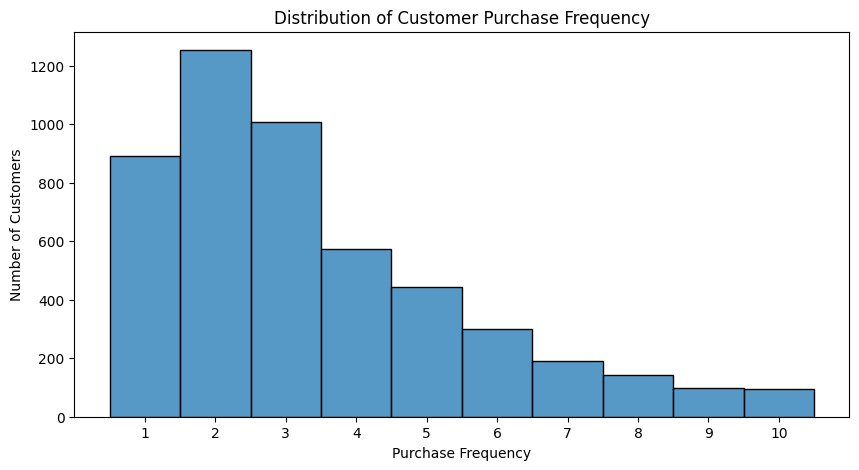

In [84]:
# Visualize purchase frequency distribution
plt.figure(figsize=(10, 5))
sns.histplot(customer_df["Purchase_Frequency"], discrete=True)

plt.title("Distribution of Customer Purchase Frequency")
plt.xlabel("Purchase Frequency")
plt.ylabel("Number of Customers")
plt.xticks(range(1, 11))
plt.show()

In [34]:
# Calculate total spending for each customer
customer_df["Monetary"] = (
    customer_df["Customer_ID"].map(
        df_copy.groupby("Customer_ID")["Total_Amount"].sum()
    )
)

display(customer_df[["Customer_ID", "Monetary"]].head(10))

,Customer_ID,Monetary
0,CUST_00001,2199.63
1,CUST_00002,809.90
2,CUST_00003,3030.81
3,CUST_00004,383.22
4,CUST_00005,2422.73
5,CUST_00006,1245.83
6,CUST_00007,1331.55
7,CUST_00008,5602.29
8,CUST_00009,470.86
9,CUST_00010,1421.16


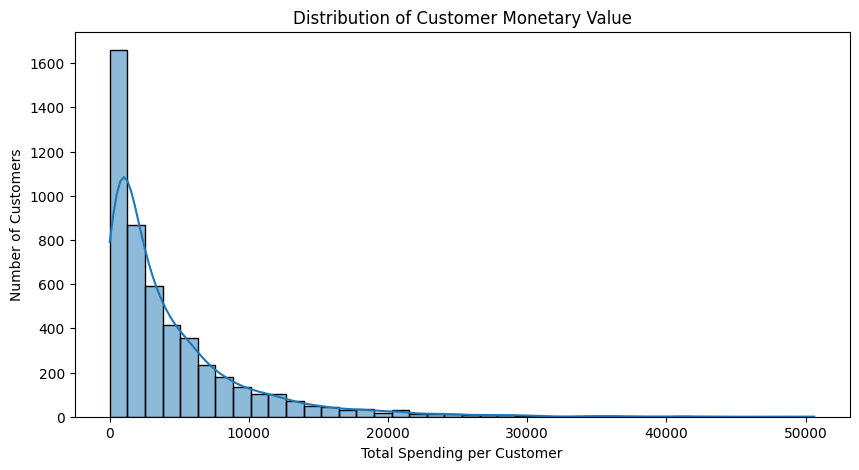

In [85]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=customer_df,
    x="Monetary",
    bins=40,
    kde=True
)

plt.title("Distribution of Customer Monetary Value")
plt.xlabel("Total Spending per Customer")
plt.ylabel("Number of Customers")
plt.show()

In [56]:
# Select RFM features
rfm_features = ["Recency", "Purchase_Frequency", "Monetary"]

X_rfm = customer_df[rfm_features].copy()

display(X_rfm.head(10))

,Recency,Purchase_Frequency,Monetary
0,112,3,2199.63
1,284,2,809.90
2,83,2,3030.81
3,42,1,383.22
4,279,3,2422.73
5,212,3,1245.83
6,81,1,1331.55
7,169,3,5602.29
8,39,1,470.86
9,22,3,1421.16


In [ ]:
from sklearn.preprocessing import StandardScaler

# Standardize RFM features using Standard Scaler
scaler = StandardScaler()

X_rfm_scaled = scaler.fit_transform(X_rfm)

display(pd.DataFrame(
    X_rfm_scaled,
    columns=rfm_features
).head(10))

,Recency,Purchase_Frequency,Monetary
0,-0.126956,-0.187850,-0.408831
1,1.465044,-0.646244,-0.672336
2,-0.395375,-0.646244,-0.251232
3,-0.774864,-1.104639,-0.753238
4,1.418765,-0.187850,-0.366529
5,0.798625,-0.187850,-0.589679
6,-0.413887,-1.104639,-0.573426
7,0.400625,-0.187850,0.236343
8,-0.802631,-1.104639,-0.736620
9,-0.959980,-0.187850,-0.556435


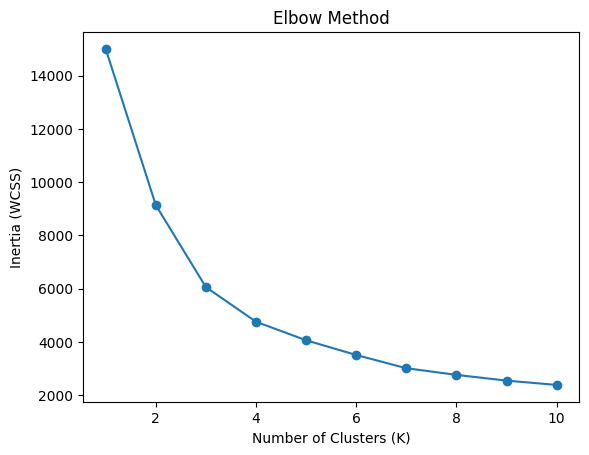

In [ ]:
from sklearn.cluster import KMeans

# Apply the Elbow Method to determine the optimal number of clusters
inertias = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10,
        max_iter=100
    )
    kmeans.fit(X_rfm_scaled)
    inertias.append(kmeans.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method")
plt.show()

In [59]:
from sklearn.metrics import silhouette_score

silhouette_scores = {}

for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10,
        max_iter=100
    )

    labels = kmeans.fit_predict(X_rfm_scaled)

    score = silhouette_score(X_rfm_scaled, labels)
    silhouette_scores[k] = score

    print(f"K={k} | Silhouette Score: {score:.4f}")

optimal_k = max(silhouette_scores, key=silhouette_scores.get)

print(f"\nOptimal K: {optimal_k}")

K=2 | Silhouette Score: 0.3952
K=3 | Silhouette Score: 0.3884
K=4 | Silhouette Score: 0.3746
K=5 | Silhouette Score: 0.3266
K=6 | Silhouette Score: 0.3128

Optimal K: 2


In [64]:
# Train K-Means with 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10,
    max_iter=100
)

# Fit the model and assign cluster labels
customer_df["Cluster"] = kmeans.fit_predict(X_rfm_scaled)

display(customer_df.head(10))

,Customer_ID,Recency,Purchase_Frequency,Monetary,Cluster
0,CUST_00001,112,3,2199.63,0
1,CUST_00002,284,2,809.90,2
2,CUST_00003,83,2,3030.81,0
3,CUST_00004,42,1,383.22,0
4,CUST_00005,279,3,2422.73,2
5,CUST_00006,212,3,1245.83,2
6,CUST_00007,81,1,1331.55,0
7,CUST_00008,169,3,5602.29,0
8,CUST_00009,39,1,470.86,0
9,CUST_00010,22,3,1421.16,0


In [66]:
# Calculate the number of customers and average RFM values for each cluster
cluster_summary = customer_df.groupby("Cluster").agg(
    Customer_Count=("Customer_ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Purchase_Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

display(cluster_summary)

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,2724,78.02,2.97,2760.62
1,997,57.48,6.66,11611.55
2,1279,280.49,1.81,2097.28


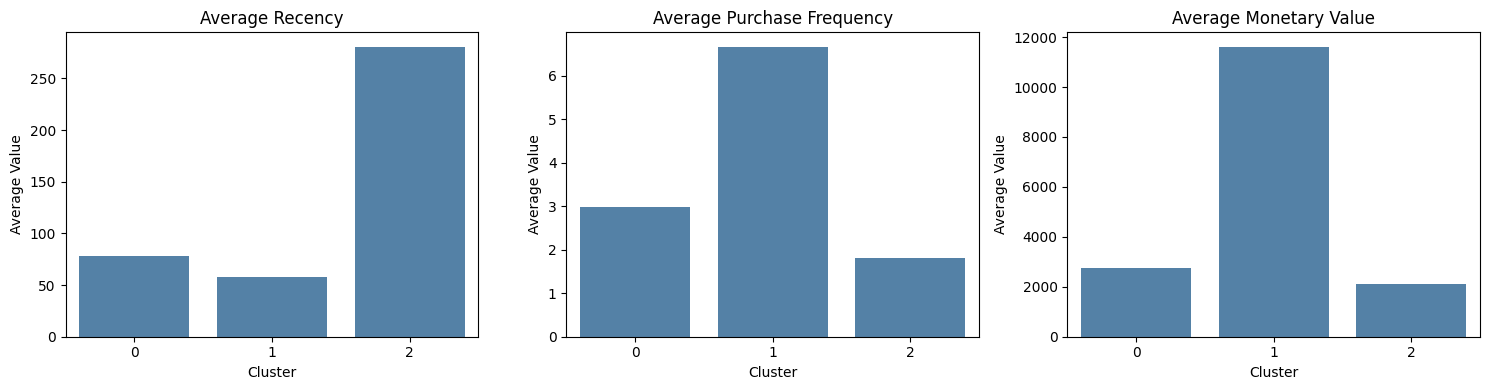

In [68]:
# Visualize average RFM values across clusters
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

features = ["Avg_Recency", "Avg_Frequency", "Avg_Monetary"]
titles = ["Average Recency", "Average Purchase Frequency", "Average Monetary Value"]

for i in range(3):
    sns.barplot(
        x=cluster_summary.index,
        y=cluster_summary[features[i]],
        ax=axes[i],
        color="steelblue"
    )
    axes[i].set_title(titles[i])
    axes[i].set_xlabel("Cluster")
    axes[i].set_ylabel("Average Value")

plt.tight_layout()
plt.show()

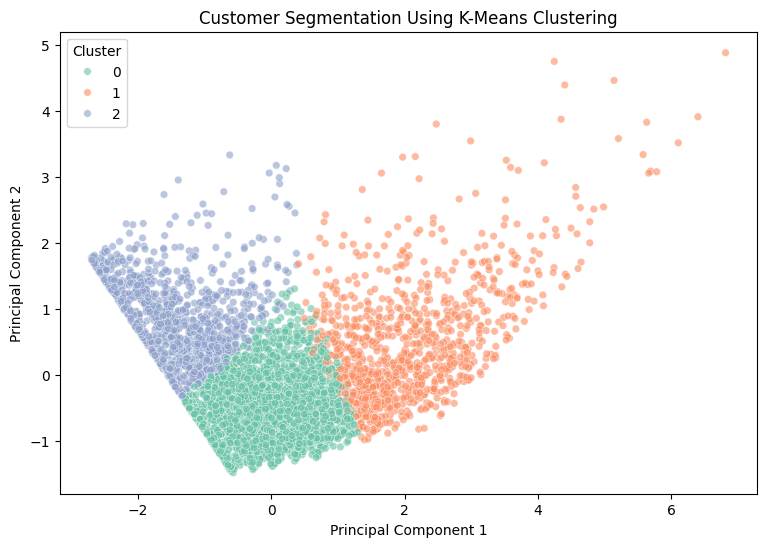

Explained Variance: 86.83%


In [87]:
from sklearn.decomposition import PCA

# Reduce RFM features to 2 dimensions using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_rfm_scaled)

# Create a DataFrame for visualization
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Cluster"] = customer_df["Cluster"].values

# Visualize customer clusters
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    alpha=0.6,
    s=30
)

plt.title("Customer Segmentation Using K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

print(f"Explained Variance: {pca.explained_variance_ratio_.sum():.2%}")